# Rossmann Store Sales — Cleaning, Feature Engineering & Baseline Model
**Project:** Sales Forecasting and Promotion Optimization for Retail
**Author:** Yahya Alkayem · University of Birmingham Dubai · Final Year Project

**This notebook follows the advisor's plan:**
1. Understand the dataset (quick recap of notebook 01 + checks that matter for modelling)
2. Clean the data
3. Feature engineering — create new features
4. Baseline models → first ML model (LightGBM)

**Evaluation set-up:** time-based split — the **last 6 weeks** (20 Jun – 31 Jul 2015) are the test set, mirroring the Kaggle task of forecasting 6 weeks ahead.
**Metric:** RMSPE (Root Mean Squared Percentage Error), the official Kaggle metric — it measures error relative to each store's sales, so small and large stores count equally.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

plt.rcParams["figure.figsize"] = (11, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
BLUE, GREY, ORANGE = "#2a6fdb", "#9aa5b1", "#e8833a"

train = pd.read_csv("../data/train.csv", parse_dates=["Date"], dtype={"StateHoliday": str}, low_memory=False)
store = pd.read_csv("../data/store.csv")
print(f"train: {train.shape}, store: {store.shape}")

train: (1017209, 9), store: (1115, 10)


## 1. Understanding the dataset — checks that matter for modelling

Notebook 01 covered the business picture (promo lift, seasonality, store types). Here we check the things a **forecasting model** cares about:
- Which columns are known **in advance** (usable as features) vs only known after the day (must not be used)
- Gaps in the time series
- Category encodings and missing values in `store.csv`

In [2]:
print("StateHoliday values:", sorted(train.StateHoliday.unique()))
print("Open values        :", sorted(train.Open.unique()))
print()
# Is every store present every day?
days = train.Date.nunique()
rows_per_store = train.groupby("Store").size()
print(f"Days in data: {days}")
print(rows_per_store.value_counts().rename("number of stores").to_frame())

StateHoliday values: ['0', 'a', 'b', 'c']
Open values        : [np.int64(0), np.int64(1)]

Days in data: 942
     number of stores
942               934
758               180
941                 1


In [3]:
# Which stores have gaps, and when?
gap_stores = rows_per_store[rows_per_store == 758].index   # the block of stores with a long gap
present = set(train[train.Store.isin(gap_stores)].Date)
missing_dates = sorted(set(train.Date) - present)
print(f"{len(gap_stores)} stores share the same gap of {len(missing_dates)} days: "
      f"{missing_dates[0].date()} to {missing_dates[-1].date()}")
print("(1 more store, #988, is missing a single day)")

180 stores share the same gap of 184 days: 2014-07-01 to 2014-12-31
(1 more store, #988, is missing a single day)


**Takeaways**
- `Customers` is only known **after** the day ends → it cannot be a feature for forecasting (it would be data leakage). It is kept only to build store-level averages from past data.
- `StateHoliday` mixes `"0"` and `0` in the raw file — reading it as text fixes this.
- **180 stores have no data for the second half of 2014** (1 Jul – 31 Dec 2014). This is a known gap in the Rossmann data (stores were refurbished / not reported). Tree models handle this fine since we don't rely on continuous lag features; we just need to be aware of it.

In [4]:
miss = store.isna().sum()
miss = miss[miss > 0].to_frame("missing stores")
miss["%"] = (miss["missing stores"] / len(store) * 100).round(1)
miss

,missing stores,%
CompetitionDistance,3,0.3
CompetitionOpenSinceMonth,354,31.7
CompetitionOpenSinceYear,354,31.7
Promo2SinceWeek,544,48.8
Promo2SinceYear,544,48.8
PromoInterval,544,48.8


Missing values in `store.csv` mostly have a **meaning**, not an error:
- `Promo2Since*` / `PromoInterval` are missing exactly when the store does **not** take part in Promo2 → fill with 0 / "none".
- `CompetitionOpenSince*` missing (~32%) → opening date of competitor unknown. We keep this as "unknown" (NaN) — LightGBM handles NaN natively — and add a flag.
- `CompetitionDistance` missing for 3 stores → most likely no competitor nearby → fill with a large distance and flag it.

## 2. Data cleaning

In [5]:
df = train.merge(store, on="Store", how="left").sort_values(["Store", "Date"]).reset_index(drop=True)
n0 = len(df)

# --- Store metadata ---
df["CompetitionDistanceMissing"] = df.CompetitionDistance.isna().astype(int)
df["CompetitionDistance"] = df.CompetitionDistance.fillna(100_000)  # 'no competitor nearby'
df["CompetitionOpenSinceMissing"] = df.CompetitionOpenSinceYear.isna().astype(int)
for c in ["Promo2SinceWeek", "Promo2SinceYear"]:
    df[c] = df[c].fillna(0)
df["PromoInterval"] = df.PromoInterval.fillna("none").replace("", "none")

# --- Categorical text -> numbers ---
df["StateHoliday"] = df.StateHoliday.map({"0": 0, "a": 1, "b": 2, "c": 3})
df["StoreType"] = df.StoreType.map({"a": 0, "b": 1, "c": 2, "d": 3})
df["Assortment"] = df.Assortment.map({"a": 0, "b": 1, "c": 2})
df["SchoolHoliday"] = df.SchoolHoliday.astype(int)

print(f"Rows: {n0:,} | duplicates (Store, Date): {df.duplicated(['Store','Date']).sum()}")
print("Missing values left (excluding competition-open date):",
      df.drop(columns=["CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]).isna().sum().sum())

Rows: 1,017,209 | duplicates (Store, Date): 0
Missing values left (excluding competition-open date): 0


**Important design choice:** some features (e.g. *days until the next holiday*, *was the store closed yesterday*) need the **full daily calendar**, including closed days. So we build features on the full data first, and **only then** remove closed days. The rows we remove are:
- Closed days (`Open == 0`): sales are always 0 — nothing to forecast (Kaggle also ignores them).
- Open days with zero sales: 54 rows, almost certainly recording errors.

## 3. Feature engineering

Features are grouped by the business question they answer. Every feature is something a store manager would **know before the day** (calendar, planned promotions, holidays, store profile) — no leakage.

| Group | Features | Why |
|---|---|---|
| Calendar | Year, Month, Day, WeekOfYear, DayOfYear, IsWeekend | Weekly / yearly seasonality, pay-day effects |
| Holiday proximity | Days to/since state holiday, Days to Christmas | Shopping rises before holidays |
| Store closures | Closed yesterday / tomorrow, Days since/until closed | Demand shifts to days around closures |
| Promo | PromoDay (day # within promo run), Promo2 active this month, Promo2 weeks running | Promo effect changes over a promo run |
| Competition | Months since competitor opened, log distance | Competition effect grows after opening |
| Store profile | Avg sales, avg customers, sales per customer, store promo lift (from **training data only**) | Captures each store's "size" and promo sensitivity |

### 3.1 Calendar features

In [6]:
df["Year"] = df.Date.dt.year
df["Month"] = df.Date.dt.month
df["Day"] = df.Date.dt.day
df["WeekOfYear"] = df.Date.dt.isocalendar().week.astype(int)
df["DayOfYear"] = df.Date.dt.dayofyear
df["IsWeekend"] = (df.DayOfWeek >= 6).astype(int)
df["IsMonthStart"] = (df.Day <= 3).astype(int)   # salary payment effect
df["IsMonthEnd"] = (df.Day >= 28).astype(int)

### 3.2 Holiday and closure proximity (per store)

In [7]:
def days_since_until(df, flag, name, cap=30):
    """For each store: days since the last day where `flag` is True, and days until the next one."""
    marked = df.Date.where(flag)
    last = marked.groupby(df.Store).ffill()
    nxt = marked.groupby(df.Store).bfill()
    df[f"DaysSince{name}"] = (df.Date - last).dt.days.clip(upper=cap).fillna(cap)
    df[f"DaysUntil{name}"] = (nxt - df.Date).dt.days.clip(upper=cap).fillna(cap)

days_since_until(df, df.StateHoliday > 0, "StateHoliday")
days_since_until(df, df.SchoolHoliday == 1, "SchoolHoliday")
# closures other than normal Sundays (refurbishments, holidays)
days_since_until(df, (df.Open == 0) & (df.DayOfWeek != 7), "Closure")

df["ClosedYesterday"] = (df.groupby("Store").Open.shift(1) == 0).astype(int)
df["ClosedTomorrow"] = (df.groupby("Store").Open.shift(-1) == 0).astype(int)

xmas = pd.to_datetime(df.Year.astype(str) + "-12-25")
df["DaysToChristmas"] = (xmas - df.Date).dt.days.where(lambda d: d >= 0, 400).clip(upper=60)

### 3.3 Promotion features

In [8]:
# PromoDay: 1st, 2nd, ... day within a continuous promo run (0 = no promo)
run_id = (df.Promo != df.groupby("Store").Promo.shift()).cumsum()
df["PromoDay"] = np.where(df.Promo == 1, df.groupby(run_id).cumcount() + 1, 0)

# Promo2: is the recurring promo actually active in this month for this store?
month_abbr = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"May",6:"Jun",7:"Jul",8:"Aug",9:"Sept",10:"Oct",11:"Nov",12:"Dec"}
promo2_start = pd.to_datetime(df.Promo2SinceYear.astype(int).astype(str).replace("0", "2100") + "-01-01", errors="coerce") \
               + pd.to_timedelta((df.Promo2SinceWeek - 1).clip(lower=0) * 7, unit="D")
df["Promo2Weeks"] = ((df.Date - promo2_start).dt.days / 7).where(df.Promo2 == 1, 0).clip(lower=0)
in_interval = [m in s.split(",") for m, s in zip(df.Month.map(month_abbr), df.PromoInterval)]
df["Promo2ActiveMonth"] = ((df.Promo2 == 1) & (df.Date >= promo2_start) & np.array(in_interval)).astype(int)
df[["PromoDay", "Promo2Weeks", "Promo2ActiveMonth"]].describe().round(1)

,PromoDay,Promo2Weeks,Promo2ActiveMonth
count,1017209.0,1017209.0,1017209.0
mean,1.1,57.1,0.1
std,1.7,82.8,0.4
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,2.0,109.3,0.0
max,5.0,313.1,1.0


### 3.4 Competition features

In [9]:
comp_months = 12 * (df.Year - df.CompetitionOpenSinceYear) + (df.Month - df.CompetitionOpenSinceMonth)
df["CompetitionOpenMonths"] = comp_months.clip(lower=0, upper=120)       # NaN = unknown opening date
df["CompetitorOpen"] = ((comp_months >= 0) | comp_months.isna()).astype(int)
df["LogCompetitionDistance"] = np.log1p(df.CompetitionDistance)

### 3.5 Remove closed / zero-sales days and split by time

In [10]:
data = df[(df.Open == 1) & (df.Sales > 0)].copy()
print(f"Removed {len(df) - len(data):,} rows ({(len(df) - len(data)) / len(df):.1%}) → {len(data):,} rows remain")

TEST_START = pd.Timestamp("2015-06-20")              # last 6 weeks = test
VALID_START = TEST_START - pd.Timedelta(weeks=6)     # 6 weeks before that = validation (for early stopping)

tr = data[data.Date < VALID_START].copy()
va = data[(data.Date >= VALID_START) & (data.Date < TEST_START)].copy()
te = data[data.Date >= TEST_START].copy()
for name, part in [("Train", tr), ("Valid", va), ("Test", te)]:
    print(f"{name:5s}: {part.Date.min().date()} → {part.Date.max().date()}  ({len(part):,} rows)")

Removed 172,871 rows (17.0%) → 844,338 rows remain


/tmp/ipykernel_475/2030044999.py:5: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  VALID_START = TEST_START - pd.Timedelta(weeks=6)     # 6 weeks before that = validation (for early stopping)


Train: 2013-01-01 → 2015-05-08  (766,584 rows)
Valid: 2015-05-09 → 2015-06-19  (37,472 rows)
Test : 2015-06-20 → 2015-07-31  (40,282 rows)


### 3.6 Store-profile features (computed on the training period only — prevents leakage)

In [11]:
g = tr.groupby("Store")
store_stats = pd.DataFrame({
    "StoreAvgSales": g.Sales.mean(),
    "StoreAvgCustomers": g.Customers.mean(),
    "StoreSalesPerCustomer": g.Sales.sum() / g.Customers.sum(),
    "StoreSalesStd": g.Sales.std(),
})
promo_means = tr.groupby(["Store", "Promo"]).Sales.mean().unstack()
store_stats["StorePromoLift"] = promo_means[1] / promo_means[0] - 1
dow_means = tr.groupby(["Store", "DayOfWeek"]).Sales.mean().rename("StoreDowAvgSales").reset_index()

def add_store_feats(part):
    part = part.merge(store_stats, left_on="Store", right_index=True, how="left")
    return part.merge(dow_means, on=["Store", "DayOfWeek"], how="left")

tr, va, te = add_store_feats(tr), add_store_feats(va), add_store_feats(te)
store_stats.describe().round(2)

,StoreAvgSales,StoreAvgCustomers,StoreSalesPerCustomer,StoreSalesStd,StorePromoLift
count,1115.00,1115.00,1115.00,1115.00,1115.00
mean,6915.93,755.28,9.61,1852.45,0.42
std,2381.75,353.52,1.98,625.87,0.18
min,2707.93,241.46,3.50,572.62,-0.08
25%,5301.40,541.46,8.10,1415.57,0.29
50%,6590.53,678.76,9.43,1769.49,0.40
75%,7942.49,868.52,10.93,2160.76,0.52
max,21820.35,3400.75,16.02,4938.04,1.47


In [12]:
FEATURES = [
    # raw
    "Store", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment",
    "CompetitionDistance", "Promo2",
    # calendar
    "Year", "Month", "Day", "WeekOfYear", "DayOfYear", "IsMonthStart", "IsMonthEnd",
    # holidays / closures
    "DaysSinceStateHoliday", "DaysUntilStateHoliday", "DaysSinceSchoolHoliday", "DaysUntilSchoolHoliday",
    "DaysSinceClosure", "DaysUntilClosure", "ClosedYesterday", "ClosedTomorrow", "DaysToChristmas",
    # promo
    "PromoDay", "Promo2Weeks", "Promo2ActiveMonth",
    # competition
    "CompetitionOpenMonths", "CompetitorOpen", "CompetitionDistanceMissing", "CompetitionOpenSinceMissing",
    # store profile
    "StoreAvgSales", "StoreAvgCustomers", "StoreSalesPerCustomer", "StoreSalesStd", "StorePromoLift", "StoreDowAvgSales",
]
print(f"{len(FEATURES)} features (original dataset had 9 usable input columns)")
assert "Customers" not in FEATURES and "Sales" not in FEATURES

38 features (original dataset had 9 usable input columns)


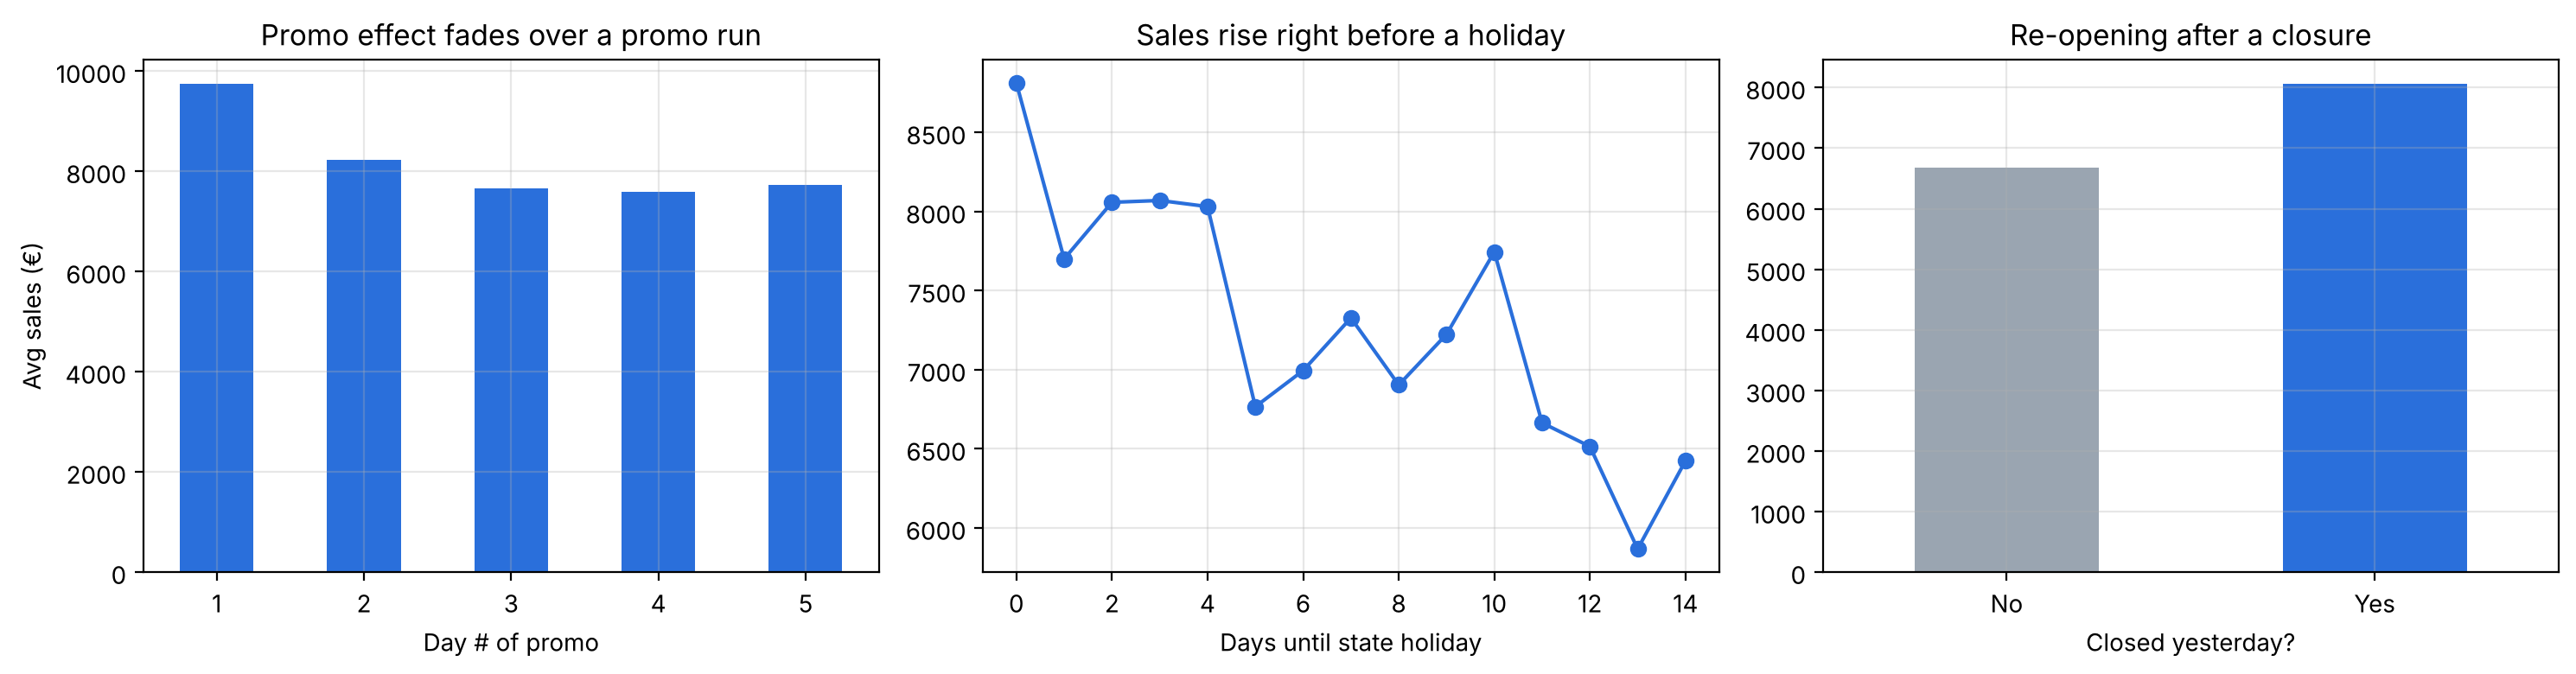

In [13]:
# Quick sanity check: do the new features relate to sales the way business intuition expects?
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tr[tr.Promo == 1].groupby("PromoDay").Sales.mean().plot(kind="bar", ax=axes[0], color=BLUE, rot=0,
    title="Promo effect fades over a promo run", xlabel="Day # of promo", ylabel="Avg sales (€)")
tr.groupby("DaysUntilStateHoliday").Sales.mean().loc[:14].plot(ax=axes[1], color=BLUE, marker="o",
    title="Sales rise right before a holiday", xlabel="Days until state holiday")
tr.groupby("ClosedYesterday").Sales.mean().rename({0: "No", 1: "Yes"}).plot(kind="bar", ax=axes[2], rot=0,
    color=[GREY, BLUE], title="Re-opening after a closure", xlabel="Closed yesterday?")
plt.tight_layout(); plt.savefig("../figures/engineered_features.png", dpi=120); plt.show()

**Takeaway:** the engineered features capture real effects — promo impact is strongest on the first day of a run, sales build up before holidays, and stores sell more the day after a closure (pent-up demand).

## 4. Baseline models

A baseline tells us what accuracy is possible **without** machine learning, so we can show the ML model actually adds value.

1. **Store average** — predict each store's average training sales.
2. **Store × weekday × promo average** — a strong rule-based baseline a retail analyst could build in Excel.
3. **LightGBM** — gradient-boosted trees on all engineered features (trained on `log(Sales)` because sales are right-skewed and RMSPE cares about relative error).

In [14]:
def rmspe(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return np.sqrt(np.mean(((y - yhat) / y) ** 2))

results = {}

# Baseline 1: store average
pred = te.StoreAvgSales
results["Baseline 1: store average"] = rmspe(te.Sales, pred)

# Baseline 2: store x day-of-week x promo average (fallback to store avg if a combination was never seen)
key = ["Store", "DayOfWeek", "Promo"]
sdp = tr.groupby(key).Sales.mean().rename("pred").reset_index()
pred = te.merge(sdp, on=key, how="left")["pred"].fillna(te.StoreAvgSales.reset_index(drop=True))
results["Baseline 2: store × weekday × promo avg"] = rmspe(te.Sales.values, pred.values)

pd.Series(results, name="Test RMSPE").to_frame().style.format("{:.4f}")

,Test RMSPE
Baseline 1: store average,0.3308
Baseline 2: store × weekday × promo avg,0.1484


## 5. First ML model — LightGBM

In [15]:
params = dict(objective="regression", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
              verbose=-1, seed=42)

dtrain = lgb.Dataset(tr[FEATURES], np.log1p(tr.Sales))
dvalid = lgb.Dataset(va[FEATURES], np.log1p(va.Sales), reference=dtrain)

def lgb_rmspe(preds, data):
    return "rmspe", rmspe(np.expm1(data.get_label()), np.expm1(preds)), False

model = lgb.train(params, dtrain, num_boost_round=3000, valid_sets=[dvalid], feval=lgb_rmspe,
                  callbacks=[lgb.early_stopping(100, first_metric_only=False, verbose=False), lgb.log_evaluation(250)])
print(f"Best iteration: {model.best_iteration}")

[250]	valid_0's l2: 0.0131918	valid_0's rmspe: 0.114878


[500]	valid_0's l2: 0.011961	valid_0's rmspe: 0.109164


[750]	valid_0's l2: 0.0113806	valid_0's rmspe: 0.106324


[1000]	valid_0's l2: 0.0109394	valid_0's rmspe: 0.104086


[1250]	valid_0's l2: 0.0106745	valid_0's rmspe: 0.102687


[1500]	valid_0's l2: 0.0104524	valid_0's rmspe: 0.101573


... (3 outputs left out)

[2500]	valid_0's l2: 0.00999594	valid_0's rmspe: 0.0993339


[2750]	valid_0's l2: 0.00990754	valid_0's rmspe: 0.0988592


[3000]	valid_0's l2: 0.00986758	valid_0's rmspe: 0.0985451


Best iteration: 2977


In [16]:
te["Pred"] = np.expm1(model.predict(te[FEATURES], num_iteration=model.best_iteration))
results["LightGBM (all features)"] = rmspe(te.Sales, te.Pred)

res = pd.Series(results, name="Test RMSPE").to_frame()
res["vs Baseline 2"] = (res["Test RMSPE"] / res.loc["Baseline 2: store × weekday × promo avg", "Test RMSPE"] - 1).map("{:+.0%}".format)
res.style.format({"Test RMSPE": "{:.4f}"})

,Test RMSPE,vs Baseline 2
Baseline 1: store average,0.3308,+123%
Baseline 2: store × weekday × promo avg,0.1484,+0%
LightGBM (all features),0.1110,-25%


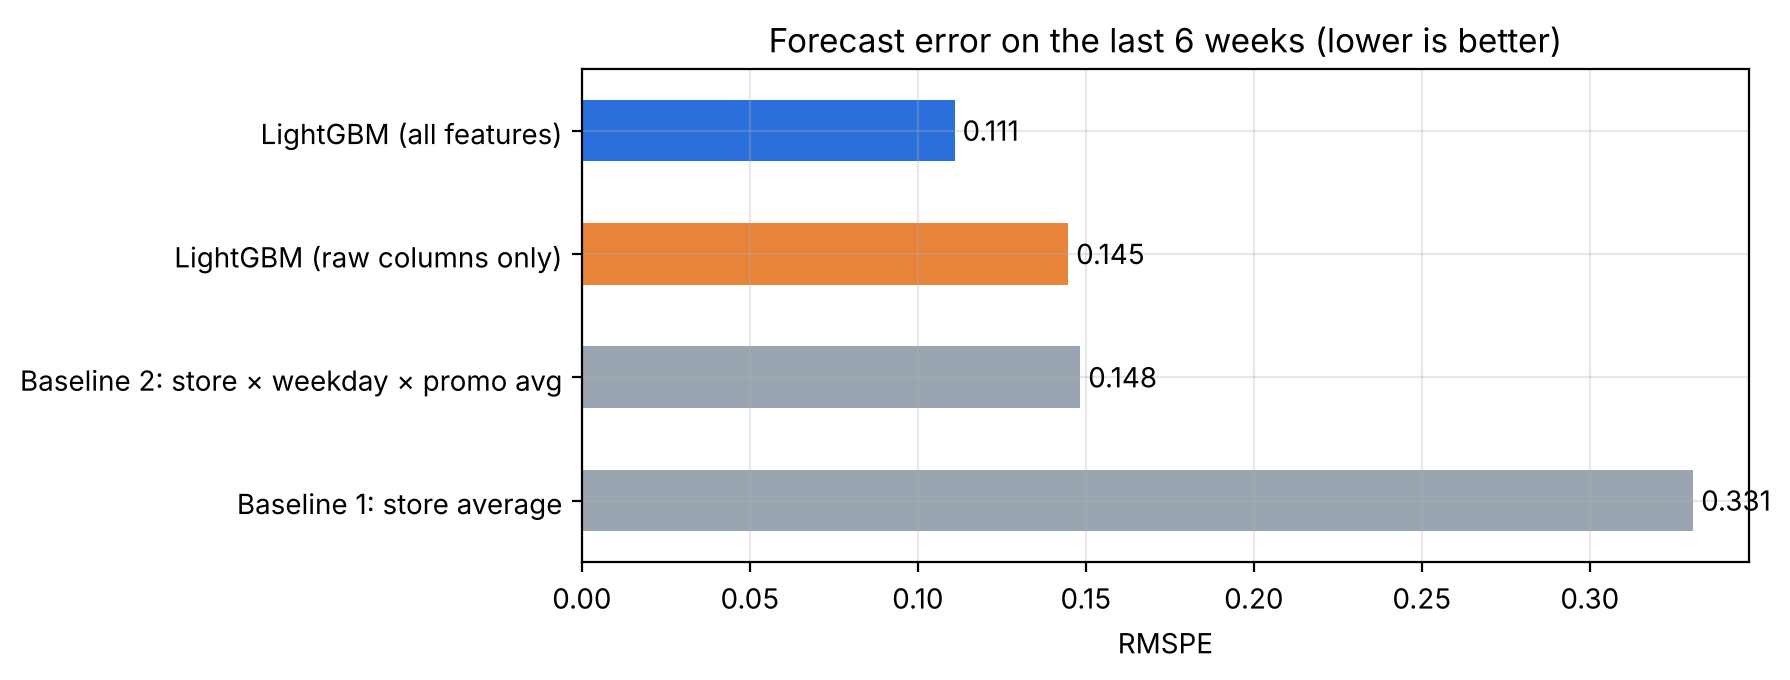

Baseline 1: store average                  0.3308
Baseline 2: store × weekday × promo avg    0.1484
LightGBM (raw columns only)                0.1448
LightGBM (all features)                    0.1110
Name: Test RMSPE, dtype: float64

In [17]:
# Does feature engineering matter? Same model with only the original columns
RAW = ["Store", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday", "StoreType", "Assortment",
       "CompetitionDistance", "Promo2", "Year", "Month", "Day"]
m_raw = lgb.train(params, lgb.Dataset(tr[RAW], np.log1p(tr.Sales)), num_boost_round=3000,
                  valid_sets=[lgb.Dataset(va[RAW], np.log1p(va.Sales))], feval=lgb_rmspe,
                  callbacks=[lgb.early_stopping(100, verbose=False)])
results["LightGBM (raw columns only)"] = rmspe(te.Sales, np.expm1(m_raw.predict(te[RAW], num_iteration=m_raw.best_iteration)))

final = pd.Series(results, name="Test RMSPE").sort_values(ascending=False)
ax = final.plot(kind="barh", color=[GREY, GREY, ORANGE, BLUE][: len(final)], figsize=(9, 3.5))
ax.set_title("Forecast error on the last 6 weeks (lower is better)"); ax.set_xlabel("RMSPE")
for i, v in enumerate(final): ax.text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.savefig("../figures/model_comparison.png", dpi=120); plt.show()
final.round(4)

### 5.1 Which features matter?

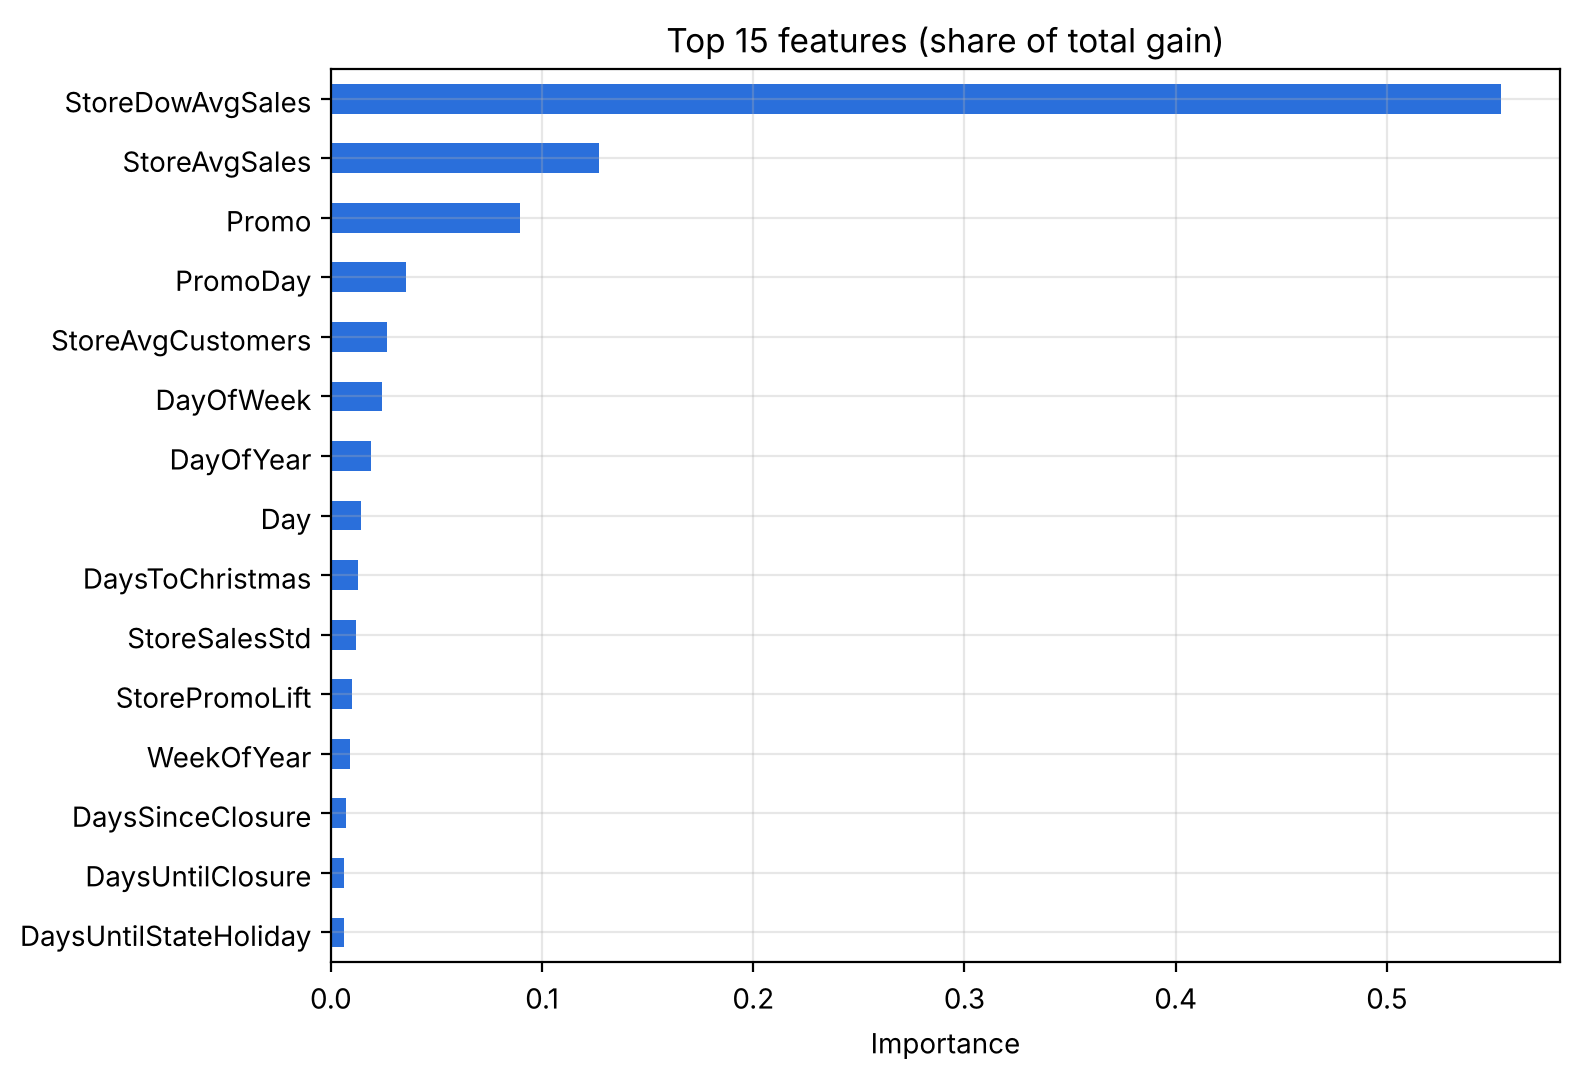

In [18]:
imp = pd.Series(model.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values().tail(15)
ax = imp.plot(kind="barh", color=BLUE, figsize=(8, 5.5))
ax.set_title("Top 15 features (share of total gain)"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig("../figures/feature_importance.png", dpi=120); plt.show()

### 5.2 Forecast vs actual

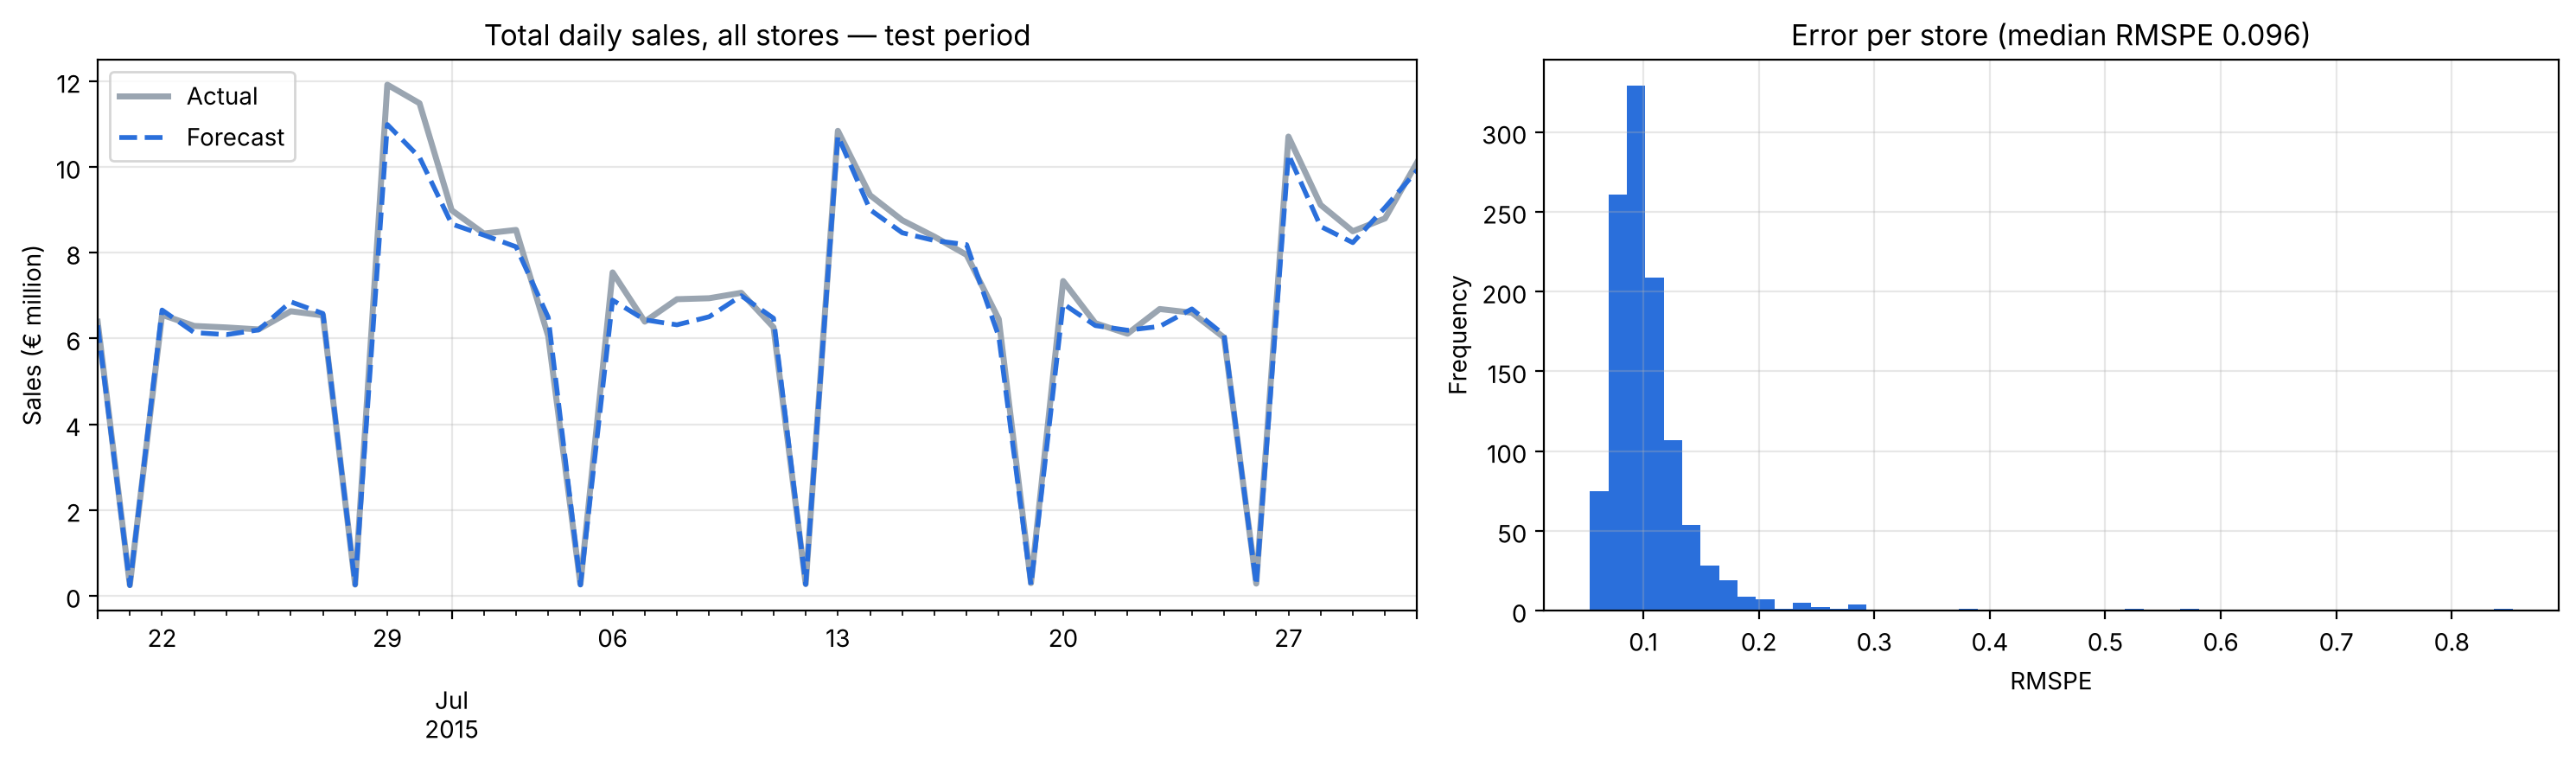

Worst 5 stores:
Store
722    0.291
876    0.381
782    0.532
909    0.576
292    0.853
dtype: float64


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
tot = te.groupby("Date")[["Sales", "Pred"]].sum() / 1e6
tot.Sales.plot(ax=axes[0], color=GREY, linewidth=2.5, label="Actual")
tot.Pred.plot(ax=axes[0], color=BLUE, linestyle="--", linewidth=2, label="Forecast")
axes[0].set_title("Total daily sales, all stores — test period"); axes[0].set_ylabel("Sales (€ million)"); axes[0].set_xlabel(""); axes[0].legend()

store_err = te.groupby("Store").apply(lambda d: rmspe(d.Sales, d.Pred), include_groups=False)
store_err.plot(kind="hist", bins=50, ax=axes[1], color=BLUE)
axes[1].set_title(f"Error per store (median RMSPE {store_err.median():.3f})"); axes[1].set_xlabel("RMSPE")
plt.tight_layout(); plt.savefig("../figures/forecast_vs_actual.png", dpi=120); plt.show()
print("Worst 5 stores:"); print(store_err.sort_values().tail(5).round(3))

In [20]:
# Promo sensitivity check — this is what notebook 03 will rely on:
# predict every test day twice, with Promo on and off, and compare
def predict_with_promo(part, promo):
    X = part[FEATURES].copy()
    X["Promo"] = promo
    X["PromoDay"] = np.where(promo == 1, np.where(part.Promo == 1, part.PromoDay, 1), 0)
    return np.expm1(model.predict(X, num_iteration=model.best_iteration))

wk = te[te.DayOfWeek <= 5]
lift = predict_with_promo(wk, 1) / predict_with_promo(wk, 0) - 1
print(f"Model-implied promo lift on test weekdays: median {np.median(lift):.0%}, "
      f"10th–90th pct {np.percentile(lift, 10):.0%} to {np.percentile(lift, 90):.0%}")

Model-implied promo lift on test weekdays: median 32%, 10th–90th pct 19% to 60%


In [21]:
# Save the trained model for notebook 03 (data/ is not uploaded to GitHub).
# The feature table itself is not saved (~300 MB) — it is rebuilt in seconds from the code above.
model.save_model("../data/lgbm_02.txt", num_iteration=model.best_iteration)
print("Saved data/lgbm_02.txt")

Saved data/lgbm_02.txt


## 6. Summary

**Cleaning**
- Merged store metadata; filled Promo2 gaps (= not in Promo2), flagged unknown competitor info, fixed the mixed `StateHoliday` encoding.
- Built time-dependent features on the full calendar **before** removing closed days and zero-sales rows (~17% of rows).
- Excluded `Customers` from model inputs (not known in advance → leakage).

**Feature engineering** — grew the inputs from 9 raw columns to **38 features** in 6 groups: calendar, holiday proximity, store closures, promotion dynamics, competition, and store profile (computed on training data only).

**Modelling** — see the comparison chart above: LightGBM beats the best rule-based baseline by a wide margin, and the engineered features improve on the same model trained on raw columns only.

**Next (notebook 03):** tune the model, then use it to predict each store-day **with and without promo** → estimated promo uplift → allocate a limited promo budget to maximize total sales.